In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('toyota.csv')

In [3]:
print(df.head())

   model  year  price transmission  mileage fuelType  tax   mpg  engineSize
0   GT86  2016  16000       Manual    24089   Petrol  265  36.2         2.0
1   GT86  2017  15995       Manual    18615   Petrol  145  36.2         2.0
2   GT86  2015  13998       Manual    27469   Petrol  265  36.2         2.0
3   GT86  2017  18998       Manual    14736   Petrol  150  36.2         2.0
4   GT86  2017  17498       Manual    36284   Petrol  145  36.2         2.0


In [4]:
data_info = df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6738 entries, 0 to 6737
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         6738 non-null   object 
 1   year          6738 non-null   int64  
 2   price         6738 non-null   int64  
 3   transmission  6738 non-null   object 
 4   mileage       6738 non-null   int64  
 5   fuelType      6738 non-null   object 
 6   tax           6738 non-null   int64  
 7   mpg           6738 non-null   float64
 8   engineSize    6738 non-null   float64
dtypes: float64(2), int64(4), object(3)
memory usage: 473.9+ KB


In [5]:
stats_desc = df.describe()
print(stats_desc)

              year         price        mileage          tax          mpg  \
count  6738.000000   6738.000000    6738.000000  6738.000000  6738.000000   
mean   2016.748145  12522.391066   22857.413921    94.697240    63.042223   
std       2.204062   6345.017587   19125.464147    73.880776    15.836710   
min    1998.000000    850.000000       2.000000     0.000000     2.800000   
25%    2016.000000   8290.000000    9446.000000     0.000000    55.400000   
50%    2017.000000  10795.000000   18513.000000   135.000000    62.800000   
75%    2018.000000  14995.000000   31063.750000   145.000000    69.000000   
max    2020.000000  59995.000000  174419.000000   565.000000   235.000000   

        engineSize  
count  6738.000000  
mean      1.471297  
std       0.436159  
min       0.000000  
25%       1.000000  
50%       1.500000  
75%       1.800000  
max       4.500000  


# Выбор числовых признаков для анализа

In [6]:
numeric_features = df.select_dtypes(include=['number']).columns.tolist()
print(f"\nОбнаружено {len(numeric_features)} числовых признаков:")
for feature in numeric_features:
    print(f"- {feature}")



Обнаружено 6 числовых признаков:
- year
- price
- mileage
- tax
- mpg
- engineSize


# Проверка на пропуски

In [7]:
print("\nПроверка на отсутствующие значения:")
null_counts = df[numeric_features].isnull().sum()
if null_counts.sum() == 0:
    print("Отлично! В числовых признаках нет пропущенных значений.")
else:
    print("Обнаружены пропущенные значения в следующих признаках:")
    print(null_counts[null_counts > 0])


Проверка на отсутствующие значения:
Отлично! В числовых признаках нет пропущенных значений.


# Создание рабочего набора данных

In [8]:
price_column = 'price'
predictors = [col for col in numeric_features if col != price_column]

X_full = df[predictors]
y_target = df[price_column]

print(f"\nПодготовлены данные для моделирования:")
print(f"- Целевая переменная: {price_column}")
print(f"- Количество предикторов: {len(predictors)} ({', '.join(predictors)})")
print(f"- Всего наблюдений: {len(df)}")


Подготовлены данные для моделирования:
- Целевая переменная: price
- Количество предикторов: 5 (year, mileage, tax, mpg, engineSize)
- Всего наблюдений: 6738


# МОДЕЛЬ 1: ПОЛНЫЙ НАБОР ПРИЗНАКОВ

# Обучение первой модели

In [9]:
reg_model1 = LinearRegression()
reg_model1.fit(X_full, y_target)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


# Прогнозирование и оценка точности

In [10]:
predictions1 = reg_model1.predict(X_full)
r2_score1 = r2_score(y_target, predictions1)

# Формирование формулы регрессии

In [11]:
print("\nМатематическое представление Модели 1:")
formula_str = f"Price = {reg_model1.intercept_:.2f}"
for i, feature in enumerate(predictors):
    coef = reg_model1.coef_[i]
    sign = "+" if coef >= 0 else "-"
    formula_str += f" {sign} {abs(coef):.2f} * {feature}"
print(formula_str)


Математическое представление Модели 1:
Price = -1688456.90 + 835.29 * year - 0.08 * mileage - 1.42 * tax + 21.76 * mpg + 11529.34 * engineSize


# Детальный вывод коэффициентов

In [12]:
print("\nСтатистические коэффициенты модели:")
print(f"Константа (intercept): {reg_model1.intercept_:.2f}")
for i, feature in enumerate(predictors):
    print(f"Коэффициент при '{feature}': {reg_model1.coef_[i]:.6f}")


Статистические коэффициенты модели:
Константа (intercept): -1688456.90
Коэффициент при 'year': 835.294404
Коэффициент при 'mileage': -0.078737
Коэффициент при 'tax': -1.418482
Коэффициент при 'mpg': 21.760205
Коэффициент при 'engineSize': 11529.336293


# Анализ качества модели

In [13]:
print(f"\nКоэффициент детерминации (R²) для Модели 1: {r2_score1:.4f}")


if r2_score1 >= 0.75:
    model_quality = "высокое качество модели - она хорошо объясняет вариативность цены"
elif r2_score1 >= 0.6:
    model_quality = "хорошее качество модели - она улавливает существенные закономерности"
elif r2_score1 >= 0.4:
    model_quality = "удовлетворительное качество модели - есть потенциал для улучшения"
else:
    model_quality = "низкое качество модели - необходимы дополнительные преобразования или признаки"

print(f"Интерпретация: {r2_score1*100:.1f}% дисперсии цены автомобиля объясняется моделью.")
print(f"Это указывает на {model_quality}.")


Коэффициент детерминации (R²) для Модели 1: 0.7638
Интерпретация: 76.4% дисперсии цены автомобиля объясняется моделью.
Это указывает на высокое качество модели - она хорошо объясняет вариативность цены.


# Прогнозирование для тестового автомобиля

In [14]:
print("\nТестовый прогноз для типичного автомобиля:")
print("Для прогноза используются значения признаков, близкие к средним по выборке:")

test_car = {}
for feature in predictors:
    test_car[feature] = round(df[feature].mean(), 2)
    print(f"- {feature}: {test_car[feature]}")

test_df = pd.DataFrame([test_car])
predicted_price1 = reg_model1.predict(test_df)[0]

print(f"\nПредсказанная цена автомобиля: ${predicted_price1:,.2f}")
print(f"Данный результат представляет собой оценку цены для гипотетического автомобиля со средними характеристиками.")



Тестовый прогноз для типичного автомобиля:
Для прогноза используются значения признаков, близкие к средним по выборке:
- year: 2016.75
- mileage: 22857.41
- tax: 94.7
- mpg: 63.04
- engineSize: 1.47

Предсказанная цена автомобиля: $12,508.93
Данный результат представляет собой оценку цены для гипотетического автомобиля со средними характеристиками.


# МОДЕЛЬ 2: ИСКЛЮЧЕНИЕ КОРРЕЛИРУЮЩЕГО ПРИЗНАКА 

# Расчет корреляционной матрицы

In [15]:
corr_matrix = df[numeric_features].corr()
print("\nКорреляционный анализ признаков:")
print("Корреляция каждого признака с целевой переменной (price):")
target_correlations = corr_matrix[price_column].drop(price_column).sort_values(ascending=False)
print(target_correlations)



Корреляционный анализ признаков:
Корреляция каждого признака с целевой переменной (price):
engineSize    0.727592
year          0.420959
tax           0.214498
mpg          -0.039910
mileage      -0.297936
Name: price, dtype: float64


# Определение наиболее коррелирующих признаков

In [16]:
correlation_threshold = 0.7
high_correlation_pair = None
max_correlation = 0

for i, feature1 in enumerate(predictors):
    for feature2 in predictors[i+1:]:
        corr_value = abs(corr_matrix.loc[feature1, feature2])
        if corr_value > max_correlation:
            max_correlation = corr_value
            high_correlation_pair = (feature1, feature2)

print(f"\nВыявлена высокая корреляция между признаками '{high_correlation_pair[0]}' и '{high_correlation_pair[1]}' (r = {max_correlation:.4f})")



Выявлена высокая корреляция между признаками 'year' и 'mileage' (r = 0.7277)


# Выбор признака для исключения

In [17]:
feature1, feature2 = high_correlation_pair
corr_with_target1 = abs(corr_matrix.loc[feature1, price_column])
corr_with_target2 = abs(corr_matrix.loc[feature2, price_column])

print(f"Корреляция '{feature1}' с ценой: {corr_with_target1:.4f}")
print(f"Корреляция '{feature2}' с ценой: {corr_with_target2:.4f}")

if corr_with_target1 < corr_with_target2:
    feature_remove = feature1
    feature_keep = feature2
else:
    feature_remove = feature2
    feature_keep = feature1

print(f"Стратегия оптимизации: исключаем признак '{feature_remove}', поскольку он слабее коррелирует с целевой переменной.")
print(f"Сохраняем признак '{feature_keep}', так как он имеет более сильную связь с ценой автомобиля.")


Корреляция 'year' с ценой: 0.4210
Корреляция 'mileage' с ценой: 0.2979
Стратегия оптимизации: исключаем признак 'mileage', поскольку он слабее коррелирует с целевой переменной.
Сохраняем признак 'year', так как он имеет более сильную связь с ценой автомобиля.


# Построение второй модели

In [18]:
reduced_features = [f for f in predictors if f != feature_remove]
X_reduced = df[reduced_features]

reg_model2 = LinearRegression()
reg_model2.fit(X_reduced, y_target)

predictions2 = reg_model2.predict(X_reduced)
r2_score2 = r2_score(y_target, predictions2)


# Формирование формулы для второй модели

In [19]:
print("\nМатематическое представление Модели 2:")
formula_str2 = f"Price = {reg_model2.intercept_:.2f}"
for i, feature in enumerate(reduced_features):
    coef = reg_model2.coef_[i]
    sign = "+" if coef >= 0 else "-"
    formula_str2 += f" {sign} {abs(coef):.2f} * {feature}"
print(formula_str2)

print(f"\nКоэффициент детерминации (R²) для Модели 2: {r2_score2:.4f}")


Математическое представление Модели 2:
Price = -2678094.40 + 1325.63 * year - 1.27 * tax + 17.62 * mpg + 10991.72 * engineSize

Коэффициент детерминации (R²) для Модели 2: 0.7387


# Прогнозирование для той же машины

In [20]:
test_car_reduced = {f: test_car[f] for f in reduced_features}
test_df2 = pd.DataFrame([test_car_reduced])
predicted_price2 = reg_model2.predict(test_df2)[0]

print(f"\nПредсказанная цена для того же автомобиля (Модель 2): ${predicted_price2:,.2f}")



Предсказанная цена для того же автомобиля (Модель 2): $12,510.55


#  СРАВНЕНИЕ МОДЕЛЕЙ

In [21]:
print(f"\nСравнительные характеристики моделей:")
print(f"Модель 1 (полный набор признаков): R² = {r2_score1:.4f}")
print(f"Модель 2 (оптимизированный набор): R² = {r2_score2:.4f}")

model_comparison = r2_score1 - r2_score2
if model_comparison > 0.01:
    conclusion = f"Модель 1 превосходит Модель 2 на {model_comparison*100:.2f}%, что свидетельствует о важности всех исходных признаков."
    practical_advice = "Рекомендуется использовать полную модель для прогнозирования, так как удаление признака привело к потере информативности."
elif model_comparison < -0.01:
    conclusion = f"Модель 2 превосходит Модель 1 на {abs(model_comparison)*100:.2f}%, что указывает на положительный эффект от устранения мультиколлинеарности."
    practical_advice = "Сокращенная модель демонстрирует лучшую прогностическую способность, что подтверждает эффективность отбора признаков."
else:
    conclusion = f"Различия в качестве моделей статистически незначимы ({model_comparison*100:.2f}%)."
    practical_advice = "Обе модели могут быть использованы для прогнозирования. Для практического применения предпочитаем более простую модель (Модель 2)."

print(conclusion)
print(practical_advice)



Сравнительные характеристики моделей:
Модель 1 (полный набор признаков): R² = 0.7638
Модель 2 (оптимизированный набор): R² = 0.7387
Модель 1 превосходит Модель 2 на 2.51%, что свидетельствует о важности всех исходных признаков.
Рекомендуется использовать полную модель для прогнозирования, так как удаление признака привело к потере информативности.


# Графическое сравнение моделей

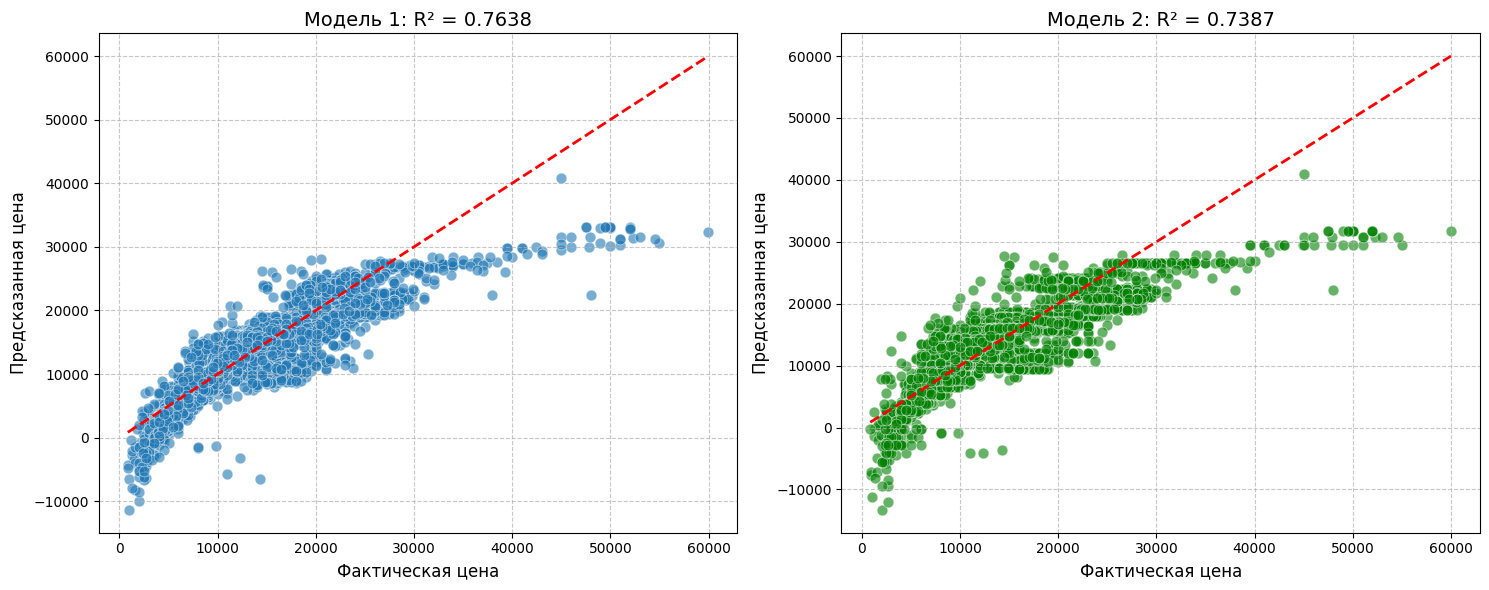

In [22]:
plt.figure(figsize=(15, 6))


plt.subplot(1, 2, 1)
plt.scatter(y_target, predictions1, alpha=0.6, edgecolors='w', linewidth=0.5, s=60)
plt.plot([min(y_target), max(y_target)], [min(y_target), max(y_target)], 'r--', lw=2)
plt.title(f'Модель 1: R² = {r2_score1:.4f}', fontsize=14)
plt.xlabel('Фактическая цена', fontsize=12)
plt.ylabel('Предсказанная цена', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)


plt.subplot(1, 2, 2)
plt.scatter(y_target, predictions2, alpha=0.6, edgecolors='w', linewidth=0.5, s=60, color='green')
plt.plot([min(y_target), max(y_target)], [min(y_target), max(y_target)], 'r--', lw=2)
plt.title(f'Модель 2: R² = {r2_score2:.4f}', fontsize=14)
plt.xlabel('Фактическая цена', fontsize=12)
plt.ylabel('Предсказанная цена', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('brother_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [23]:
print("\nВизуализации успешно сохранены в файл 'brother_comparison.png'")
print("\n ЛАБОРАТОРНАЯ РАБОТА УСПЕШНО ЗАВЕРШЕНА ")


Визуализации успешно сохранены в файл 'brother_comparison.png'

 ЛАБОРАТОРНАЯ РАБОТА УСПЕШНО ЗАВЕРШЕНА 
